# 01 Alma Maps And Fluxes


In [ ]:
from pathlib import Path

def find_project_root(start=None):
    """Locate the project root from the working directory or an ancestor."""
    location = Path(start or Path.cwd()).resolve()
    for candidate in (location, *location.parents):
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Run Jupyter from the repository root or notebooks/ directory. The README.md and notebooks/ folder must exist.")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
SPECTRA_DIR = PROJECT_ROOT / "spectra"
FIGURES_DIR = PROJECT_ROOT / "figures"
SAVE_FIGURES = False  # Figures render inline; optional exports disabled by default.
SAVE_TABLES = True    # Intermediate tables are required by downstream notebooks.
# Output folders are part of the repository layout; raw data remains private.


> **Saved results:** Figures and tables displayed below were restored from the original research notebook. They are historical outputs, not a new execution of the portable code. The source FITS files are not redistributed.


# ALMA FITS maps and simulated IRAM 30 m flux measurements

In [ ]:
# EJECUTAR ESTA CELDA ANTES DE LAS DEMÁS PARA DEFINIR VARIABLES Y RUTAS

import os
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u

# ------------------------------------------------------------
# 0. RUTA DE SALIDA
# ------------------------------------------------------------
path_results = str(RESULTS_DIR / "ResultadosCO")
os.makedirs(path_results, exist_ok=True)

# ------------------------------------------------------------
# 1. ARCHIVOS FITS
# ------------------------------------------------------------
FILE_CO10 = str(PROJECT_ROOT / 'results/ResultadosCO/line_12co10_contsub_clean20_nat.regrid.immath.moment0.fits')
FILE_CO21 = str(PROJECT_ROOT / 'results/ResultadosCO/ngc3110_co21_081011_LINE.fits.image.integrated.fits')

# ------------------------------------------------------------
# 2. FRECUENCIA DE LAS LÍNEAS
# ------------------------------------------------------------
NU_CO10_GHZ = 113.36
NU_CO21_GHZ = 226.72
NU_densegas_GHZ = 88.400

# ------------------------------------------------------------
# 3. ANCHURA DEL HAZ DEL IRAM 30m
# ------------------------------------------------------------
FWHM_CO10 = 2460 / NU_CO10_GHZ   # arcsec
FWHM_CO21 = 2460 / NU_CO21_GHZ   # arcsec
FWHM_densegas = 2460 / NU_densegas_GHZ  # arcsec

# ------------------------------------------------------------
# 4. POINTINGS EXACTOS DEL 30m
# Obtenidos del .sou
# ------------------------------------------------------------
POINTINGS = {
    "CEN": SkyCoord("10:04:02.110", "-06:28:29.200",
                    unit=(u.hourangle, u.deg), frame="icrs"),
    "NOR": SkyCoord("10:04:01.210", "-06:28:12.200",
                    unit=(u.hourangle, u.deg), frame="icrs"),
    "SOU": SkyCoord("10:04:02.500", "-06:28:48.000",
                    unit=(u.hourangle, u.deg), frame="icrs"),
}

## 1. FITS maps

ALMA FITS maps with the IRAM 30 m observation pointings corresponding to the dense-gas setup.

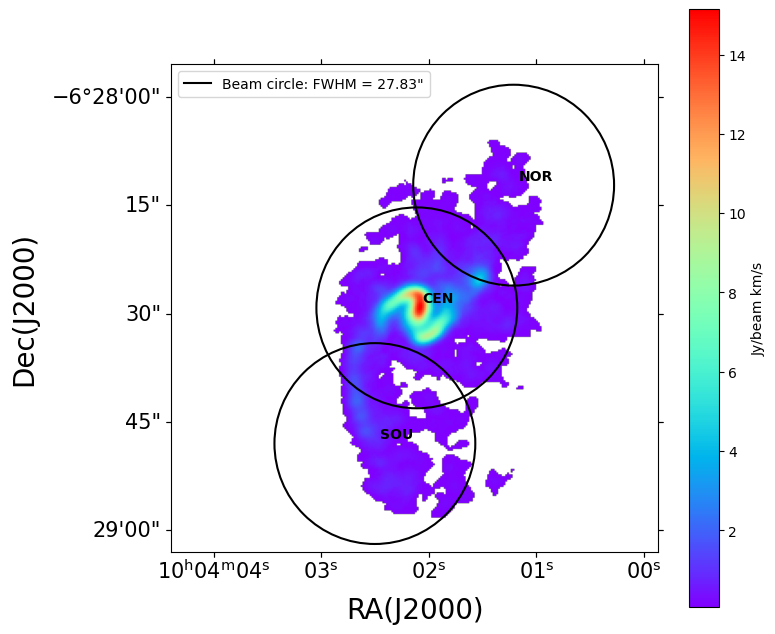

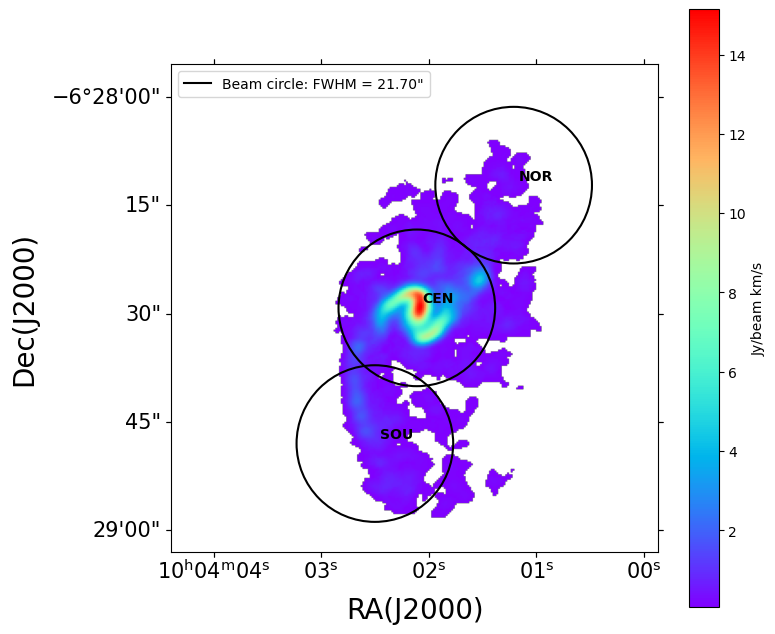

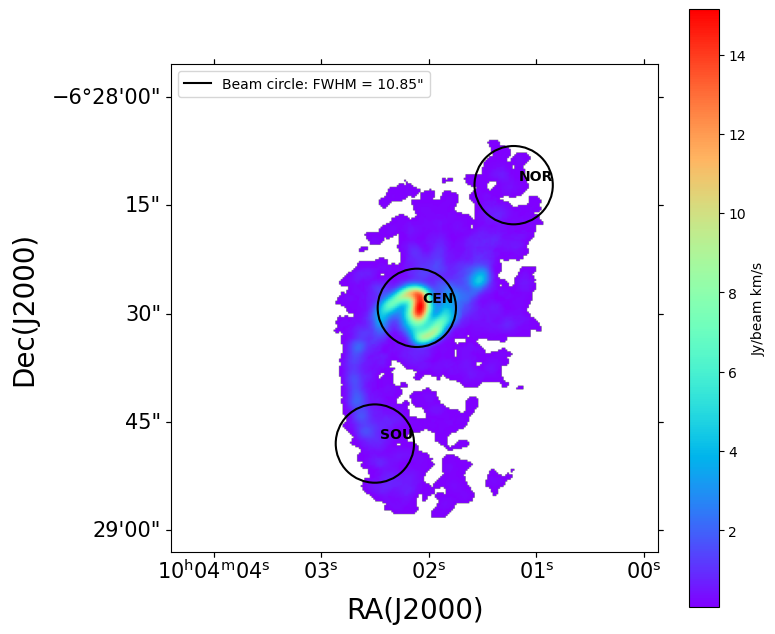

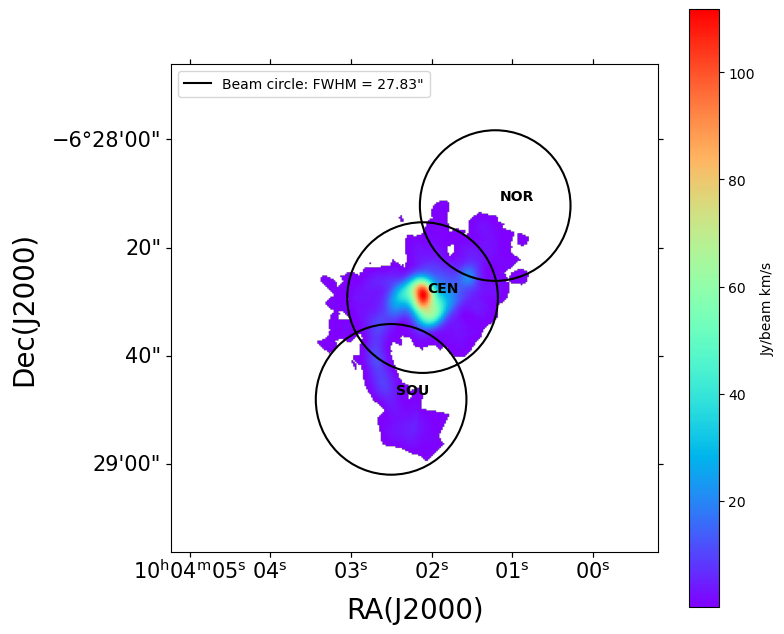

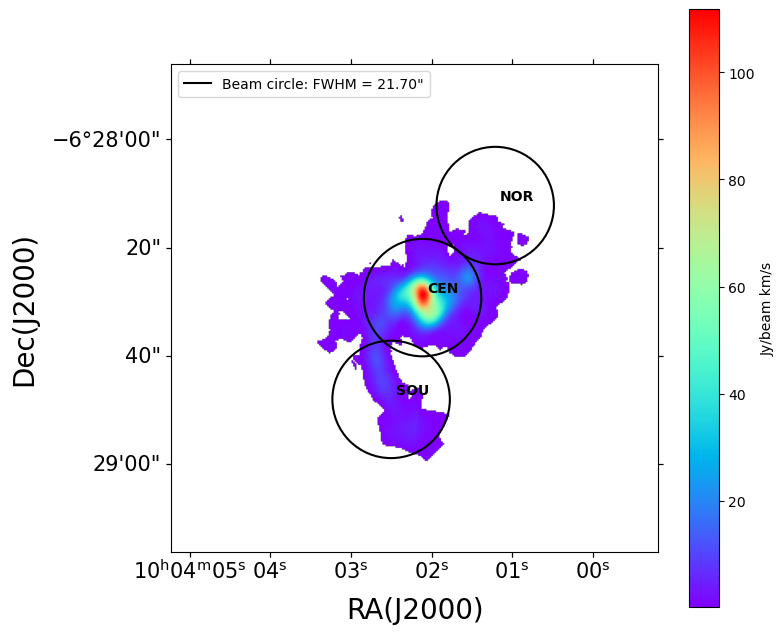

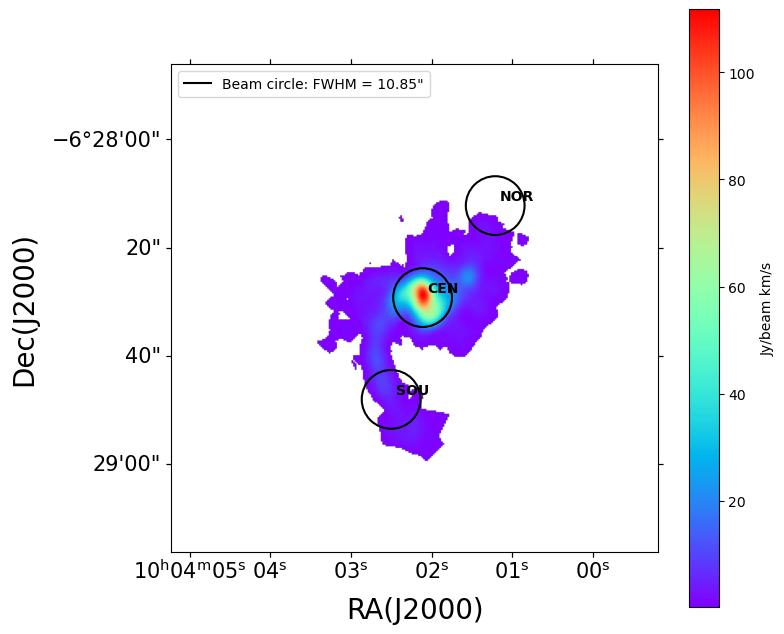

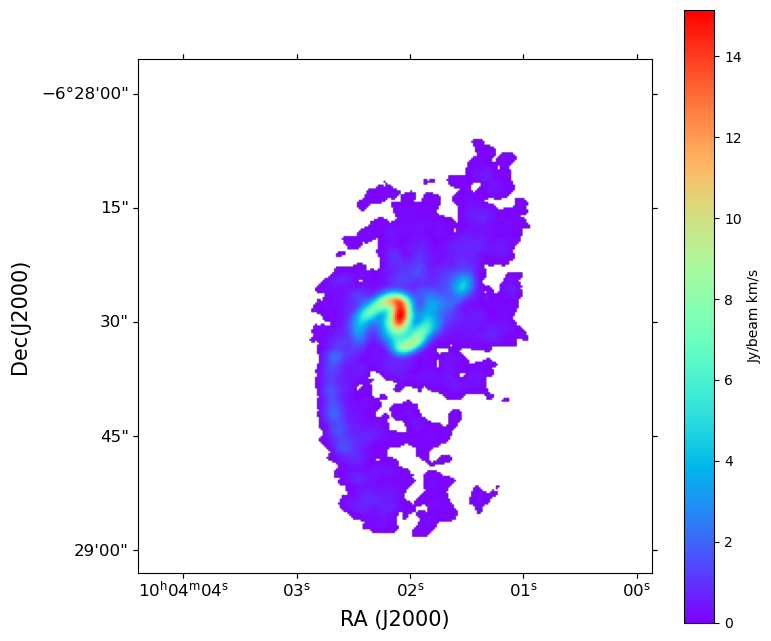

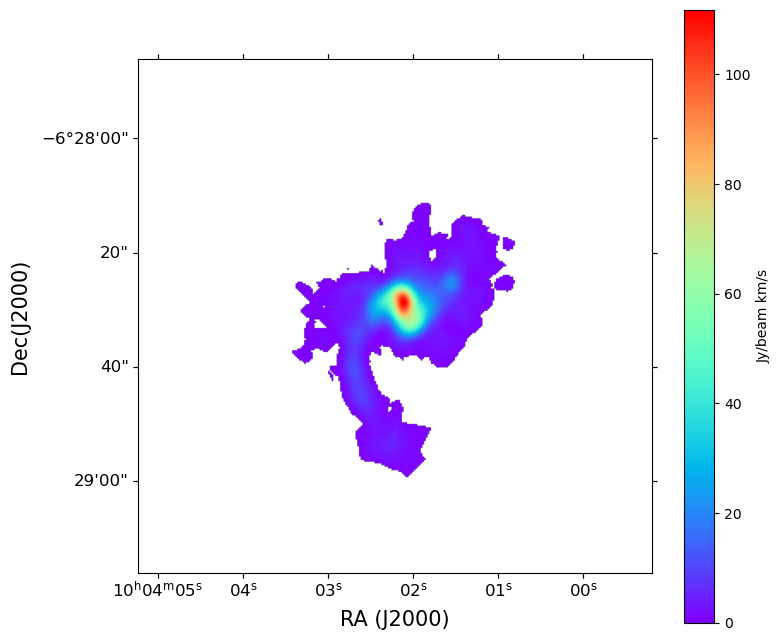

In [3]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
from astropy.wcs.utils import proj_plane_pixel_scales
from matplotlib.patches import Circle

warnings.simplefilter("ignore", FITSFixedWarning)

# ------------------------------------------------------------
# 5. FUNCIONES AUXILIARES
# ------------------------------------------------------------
def load_map(filename):
    """
    Abre un FITS, elimina ejes degenerados y devuelve:
    - data: mapa 2D
    - header: cabecera FITS
    - wcs: WCS celeste
    """
    hdu = fits.open(filename)[0]
    data = np.squeeze(hdu.data)
    header = hdu.header
    wcs = WCS(header).celestial

    if data.ndim != 2:
        raise ValueError(f"El mapa {filename} no es 2D tras squeeze. ndim = {data.ndim}")

    return data, header, wcs


def pixel_scales_arcsec(wcs):
    """
    Devuelve el tamaño angular del píxel en arcsec/pixel.
    """
    scales_deg = proj_plane_pixel_scales(wcs)
    return float(scales_deg[0] * 3600.0), float(scales_deg[1] * 3600.0)


def plot_map_with_pointings(data, wcs, title, fwhm_arcsec, vmin=None, vmax=None):
    """
    Dibuja el mapa con los tres pointings y un círculo del beam común.
    """
    pix_x_arcsec, _ = pixel_scales_arcsec(wcs)
    radius_pix_x = (fwhm_arcsec / 2.0) / pix_x_arcsec

    plt.figure(figsize=(8, 7))
    ax = plt.subplot(projection=wcs)

    image = ax.imshow(data, origin="lower", cmap="rainbow", vmin=vmin, vmax=vmax)

    cbar = plt.colorbar(image, ax=ax)
    cbar.set_label("Jy/beam km/s")

    for name, coord in POINTINGS.items():
        xpix, ypix = wcs.world_to_pixel(coord)
        circ = Circle((xpix, ypix), radius_pix_x,
                      edgecolor="black", facecolor="none", lw=1.5)
        ax.add_patch(circ)
        ax.text(xpix + 3, ypix + 3, name, color="black", fontsize=10, weight="bold")

    legend_elements = [
        Line2D([0], [0], color='black', lw=1.5, label=f'Beam circle: FWHM = {fwhm_arcsec:.2f}"')
    ]

    ax.legend(handles=legend_elements, loc="upper left")
    #ax.set_title(title)
    ax.set_xlabel("RA(J2000)", fontsize=20)
    ax.set_ylabel("Dec(J2000)", fontsize=20)
    ax.tick_params('both', labelsize=15)
    plt.tight_layout()
    plt.show() 


def plot_map_without_pointings(data, wcs, vmin=None, vmax=None):
    """
    Dibuja el mapa sin los pointings ni el círculo del beam.
    """
    plt.figure(figsize=(8, 7))
    ax = plt.subplot(projection=wcs)

    image = ax.imshow(data, origin="lower", cmap="rainbow", vmin=vmin, vmax=vmax)

    cbar = plt.colorbar(image, ax=ax)
    cbar.set_label("Jy/beam km/s")

    #ax.set_title(title)
    ax.set_xlabel("RA (J2000)", fontsize=15)
    ax.set_ylabel("Dec(J2000)", fontsize=15)
    ax.tick_params('both', labelsize=12)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 6. CARGAR MAPAS
# ------------------------------------------------------------
co10_jy, h10, w10 = load_map(FILE_CO10)
co21_jy, h21, w21 = load_map(FILE_CO21)

# ------------------------------------------------------------
# 7. DIBUJAR MAPAS EN Jy/beam km/s
# ------------------------------------------------------------

# CO(1-0) con FWHM_densegas
plot_map_with_pointings(
    co10_jy, w10,
    "NGC 3110 CO(1-0) moment 0 (Jy/beam km/s)",
    FWHM_densegas
)

# CO(1-0) con FWHM_CO10
plot_map_with_pointings(
    co10_jy, w10,
    "NGC 3110 CO(1-0) moment 0 (Jy/beam km/s)",
    FWHM_CO10
)

# CO(1-0) con FWHM_CO21
plot_map_with_pointings(
    co10_jy, w10,
    "NGC 3110 CO(1-0) moment 0 (Jy/beam km/s)",
    FWHM_CO21
)

# CO(2-1) con FWHM_densegas
plot_map_with_pointings(
    co21_jy, w21,
    "NGC 3110 CO(2-1) moment 0 (Jy/beam km/s)",
    FWHM_densegas
)

# CO(2-1) con FWHM_CO10
plot_map_with_pointings(
    co21_jy, w21,
    "NGC 3110 CO(2-1) moment 0 (Jy/beam km/s)",
    FWHM_CO10
)

# CO(2-1) con FWHM_CO21
plot_map_with_pointings(
    co21_jy, w21,
    "NGC 3110 CO(2-1) moment 0 (Jy/beam km/s)",
    FWHM_CO21
)

# CO(1-0) sin pointings
plot_map_without_pointings(
    co10_jy, w10,
    vmin=0, vmax=np.nanmax(co10_jy)
)

# CO(2-1) sin pointings
plot_map_without_pointings(
    co21_jy, w21,
    vmin=0, vmax=np.nanmax(co21_jy)
)

## 2. RMS estimation and flux calculations

Estimate the noise in the ALMA FITS maps and apply two-dimensional Gaussian weighting to simulate IRAM 30 m observations.

In [9]:
# ------------------------------------------------------------
# 5. FUNCIONES AUXILIARES
# ------------------------------------------------------------
def beam_area_ALMA_arcsec2(BMAJ, BMIN):
    """
    Área de un beam gaussiano en arcsec^2:
    Omega_beam = 1.1331 * FWHM_maj * FWHM_min
    """
    return 1.1331 * BMAJ * BMIN


def jybeam_to_surface_brightness(data_jybeam, header):
    """
    Convierte Jy/beam km/s a Jy/arcsec^2 km/s.
    """
    if "BMAJ" not in header or "BMIN" not in header:
        raise KeyError("La cabecera FITS no contiene BMAJ/BMIN.")

    bmaj_arcsec = header["BMAJ"] * 3600.0
    bmin_arcsec = header["BMIN"] * 3600.0
    omega_beam = beam_area_ALMA_arcsec2(bmaj_arcsec, bmin_arcsec)

    data_sb = data_jybeam / omega_beam
    return data_sb, omega_beam, bmaj_arcsec, bmin_arcsec


def estimate_rms_map(data, sigma_clip=3.0, max_iter=5, min_valid=30):
    """
    Estima un único rms por píxel para todo el mapa y devuelve
    un mapa 2D constante con ese valor.

    Este rms_map debe propagarse después con la gaussiana del beam:
        sigma = sqrt(sum((rms_map * gaussian_weights)**2))

    Parámetros
    ----------
    data : 2D np.ndarray
        Mapa 2D.
    sigma_clip : float
        Umbral de sigma clipping.
    max_iter : int
        Número máximo de iteraciones.
    min_valid : int
        Número mínimo de píxeles válidos.

    Devuelve
    --------
    rms_map : 2D np.ndarray
        Mapa 2D constante de rms por píxel.
    """

    data = np.asarray(data, dtype=float)

    if data.ndim != 2:
        raise ValueError("`data` debe ser un mapa 2D.")

    vals = data[np.isfinite(data)]

    if vals.size < min_valid:
        raise ValueError("No hay suficientes píxeles válidos.")

    work = vals.copy()

    for _ in range(max_iter):
        med = np.nanmedian(work)
        std = np.nanstd(work, ddof=1)

        if not np.isfinite(std) or std == 0:
            break

        mask = np.abs(work - med) < sigma_clip * std
        new_work = work[mask]

        if new_work.size == work.size:
            break
        if new_work.size < min_valid:
            break

        work = new_work

    rms_pix = np.nanstd(work, ddof=1)

    if not np.isfinite(rms_pix) or rms_pix <= 0:
        raise ValueError("No se pudo estimar un rms válido.")

    rms_map = np.full_like(data, rms_pix, dtype=float)

    return rms_map


def fwhm_to_sigma(fwhm_arcsec):
    """
    Convierte FWHM a sigma gaussiana.
    """
    return fwhm_arcsec / (2.0 * np.sqrt(2.0 * np.log(2.0)))


def gaussian_kernel(shape, x0, y0, fwhm_arcsec, wcs):
    """
    Devuelve un kernel gaussiano centrado en (x0,y0) y normalizado para que:
        sum(kernel * area_pixel) = 1

    Así, el kernel representa correctamente el beam del telescopio.
    """
    pix_x_arcsec, pix_y_arcsec = pixel_scales_arcsec(wcs)
    omega_pix = abs(pix_x_arcsec * pix_y_arcsec)

    sigma_pix = fwhm_to_sigma(fwhm_arcsec) / pix_x_arcsec

    yy, xx = np.indices(shape)

    x = xx - x0
    y = yy - y0

    kernel = np.exp(
        -0.5 * (
            (x / sigma_pix) ** 2 +
            (y / sigma_pix) ** 2
        )
    )

    norm = np.nansum(kernel) * omega_pix
    if norm == 0 or not np.isfinite(norm):
        raise ValueError("No se pudo normalizar el kernel del beam.")

    kernel /= norm
    return kernel


def simulate_single_pointing(data_jybeam, header, wcs, coord, fwhm_arcsec, frac_cal, rms_map_jybeam=None):
    """
    Simula un pointing del IRAM 30m sobre un mapa ALMA.

    Pasos:
    1) Convierte Jy/beam_ALMA -> Jy/arcsec^2
    2) Convoluciona con beam del 30m
    3) Devuelve el flujo final en Jy/beam_30m km/s

    Errores:
    - estadístico: propagado desde un rms por píxel constante convolucionado con el beam
    - sistemático: frac_cal * flujo
    """
    data_sb, omega_beam_alma, bmaj_alma, bmin_alma = jybeam_to_surface_brightness(data_jybeam, header)

    if rms_map_jybeam is None:
        rms_map_jybeam = estimate_rms_map(data_jybeam)

    # Convertir también el mapa de rms a brillo superficial
    rms_map_sb = rms_map_jybeam / omega_beam_alma

    x0, y0 = wcs.world_to_pixel(coord)

    pix_x_arcsec, pix_y_arcsec = pixel_scales_arcsec(wcs)
    omega_pix = abs(pix_x_arcsec * pix_y_arcsec)

    kernel = gaussian_kernel(data_sb.shape, x0, y0, fwhm_arcsec, wcs)

    # Brillo superficial beam-promediado en el pointing
    sb_conv = np.nansum(data_sb * kernel) * omega_pix   # Jy/arcsec^2 km/s

    # Convertir a Jy/beam_30m km/s
    omega_beam_30m = beam_area_ALMA_arcsec2(fwhm_arcsec, fwhm_arcsec)
    flux_30m = sb_conv * omega_beam_30m

    # Error estadístico propagado píxel a píxel
    weights = kernel * omega_pix
    var_stat_sb = np.nansum((weights ** 2) * (rms_map_sb ** 2))
    err_stat_sb = np.sqrt(var_stat_sb)
    err_stat_flux = err_stat_sb * omega_beam_30m

    # Error sistemático de calibración
    err_sys_flux = frac_cal * abs(flux_30m)

    # Error total
    err_tot_flux = np.hypot(err_stat_flux, err_sys_flux)

    return flux_30m, err_tot_flux, err_stat_flux, err_sys_flux


def simulate_all_pointings(data_jybeam, header, wcs, label, fwhm_arcsec, frac_cal):
    """
    Simula los tres pointings NOR/CEN/SOU y devuelve flujo y errores.
    """
    values = {}
    err_tot = {}
    err_stat = {}
    err_sys = {}

    rms_map_jybeam = estimate_rms_map(data_jybeam)

    print("\n" + "=" * 72)
    print(label)
    print("=" * 72)
    print(f"Beam 30m usado: {fwhm_arcsec:.2f}\" x {fwhm_arcsec:.2f}\"")
    print(f"RMS por píxel del mapa (Jy/beam km/s): {np.nanmedian(rms_map_jybeam):.6e}")
    print("-" * 72)

    for region, coord in POINTINGS.items():
        val, etot, estat, esys = simulate_single_pointing(
            data_jybeam, header, wcs, coord, fwhm_arcsec, frac_cal, rms_map_jybeam
        )

        values[region] = val
        err_tot[region] = etot
        err_stat[region] = estat
        err_sys[region] = esys

        print(f"{region}: {val:.6g} ± {etot:.6g} Jy/beam_30m km/s "
              f"(stat={estat:.3g}, sys={esys:.3g})")

    return values, err_tot, err_stat, err_sys


# ------------------------------------------------------------
# 6 CALCULO DE LOS FLUJOS SIMULADOS EN LOS POINTINGS DEL 30m CON INCERTIDUMBRES
# ------------------------------------------------------------ 

FRAC_CAL_CO10 = 0.05 
FRAC_CAL_CO21 = 0.1
co10_vals, co10_err, co10_err_stat, co10_err_sys = simulate_all_pointings(co10_jy, h10, w10, "CO(1-0) simulado con beam IRAM 30m", FWHM_CO10, FRAC_CAL_CO10)

co21_vals, co21_err, co21_err_stat, co21_err_sys = simulate_all_pointings(co21_jy, h21, w21, "CO(2-1) simulado con beam IRAM 30m", FWHM_CO21, FRAC_CAL_CO21)


# =====================================================================
# 6.5 CONVERSION CORRECTA DE Jy/beam_30m km/s A K km/s
# =====================================================================

def jybeam30m_to_Kkms(data_jybeam, err_jybeam, nu_ghz, fwhm_arcsec):
    """
    Convierte Jy/beam_30m km/s a K km/s usando Rayleigh-Jeans.

    data_jybeam : flujo integrado en Jy/beam_30m km/s
    err_jybeam  : error en Jy/beam_30m km/s
    nu_ghz      : frecuencia de la línea en GHz
    fwhm_arcsec : FWHM del beam usado en arcsec

    Fórmula:
    Tmb[K] = 1.222e6 * S[Jy/beam] / (nu[GHz]^2 * theta_maj["] * theta_min["])
    """

    factor = 1.222e6 / (nu_ghz**2 * fwhm_arcsec * fwhm_arcsec)

    data_K = data_jybeam * factor
    err_K = err_jybeam * factor

    return data_K, err_K, factor


co10_vals_K = {}
co10_err_K = {}
co21_vals_K = {}
co21_err_K = {}

for region in ["NOR", "CEN", "SOU"]:

    co10_vals_K[region], co10_err_K[region], factor_co10 = jybeam30m_to_Kkms(
        co10_vals[region],
        co10_err[region],
        NU_CO10_GHZ,
        FWHM_CO10
    )

    co21_vals_K[region], co21_err_K[region], factor_co21 = jybeam30m_to_Kkms(
        co21_vals[region],
        co21_err[region],
        NU_CO21_GHZ,
        FWHM_CO21
    )

print(f"\nFactor CO(1-0): {factor_co10:.5f} K/(Jy/beam)")
print(f"Factor CO(2-1): {factor_co21:.5f} K/(Jy/beam)")

# =====================================================================
# 7 SALIDA A UN FICHERO
# =====================================================================

rows = []
for region in ["NOR", "CEN", "SOU"]:

    rows.append({
        "fuente": f"NGC3110_{region}",

        "I_CO10_ALMA_Jy": co10_vals[region],
        "err_I_CO10_ALMA_Jy": co10_err[region],
        "I_CO10_ALMA_K": co10_vals_K[region],
        "err_I_CO10_ALMA_K": co10_err_K[region],

        "I_CO21_ALMA_Jy": co21_vals[region],
        "err_I_CO21_ALMA_Jy": co21_err[region],
        "I_CO21_ALMA_K": co21_vals_K[region],
        "err_I_CO21_ALMA_K": co21_err_K[region],
    })

df_out = pd.DataFrame(rows)

output_file = os.path.join(path_results, "CO_ALMA_beam30m_Jy_K.dat")
df_out.to_csv(output_file, sep="\t", index=False, float_format="%.6f")

print(f"\nTabla guardada en: {output_file}")
display(df_out)


CO(1-0) simulado con beam IRAM 30m
Beam 30m usado: 21.70" x 21.70"
RMS por píxel del mapa (Jy/beam km/s): 2.466449e-01
------------------------------------------------------------------------
CEN: 187.18 ± 9.36527 Jy/beam_30m km/s (stat=0.342, sys=9.36)
NOR: 30.9782 ± 1.58988 Jy/beam_30m km/s (stat=0.359, sys=1.55)
SOU: 49.7563 ± 2.51362 Jy/beam_30m km/s (stat=0.359, sys=2.49)

CO(2-1) simulado con beam IRAM 30m
Beam 30m usado: 10.85" x 10.85"
RMS por píxel del mapa (Jy/beam km/s): 2.357971e+00
------------------------------------------------------------------------
CEN: 353.969 ± 35.4019 Jy/beam_30m km/s (stat=0.592, sys=35.4)
NOR: 4.51947 ± 0.745103 Jy/beam_30m km/s (stat=0.592, sys=0.452)
SOU: 25.7451 ± 2.64179 Jy/beam_30m km/s (stat=0.592, sys=2.57)

Factor CO(1-0): 0.20193 K/(Jy/beam)
Factor CO(2-1): 0.20193 K/(Jy/beam)

Tabla guardada en: <PRIVATE_PROJECT_ROOT>/results/ResultadosCO/CO_ALMA_beam30m_Jy_K.dat


,fuente,I_CO10_ALMA_Jy,err_I_CO10_ALMA_Jy,I_CO10_ALMA_K,err_I_CO10_ALMA_K,I_CO21_ALMA_Jy,err_I_CO21_ALMA_Jy,I_CO21_ALMA_K,err_I_CO21_ALMA_K
0,NGC3110_NOR,30.978197,1.589879,6.255429,0.321044,4.519474,0.745103,0.912618,0.150459
1,NGC3110_CEN,187.180379,9.365273,37.797347,1.891130,353.969498,35.401906,71.477085,7.148709
2,NGC3110_SOU,49.756297,2.513620,10.047292,0.507575,25.745117,2.641786,5.198713,0.533456


## 3. Comparison of observed IRAM and simulated ALMA fluxes

Compare the ALMA CO(1–0) and CO(2–1) fluxes after simulating the IRAM 30 m beam and converting to compatible flux units.

In [10]:
# ====================================================================
# 5 FICHEROS CON LOS FLUJOS DE IRAM Y DE ALMA SIMULADOS CON BEAM DEL 30m
# ====================================================================

co_ALMA = pd.read_csv(
    os.path.join(str(PROJECT_ROOT / 'results/ResultadosCO/CO_ALMA_beam30m_Jy_K.dat')),
    sep="\t"
)

co10_ALMA = co_ALMA[["fuente", "I_CO10_ALMA_Jy", "err_I_CO10_ALMA_Jy"]]
co21_ALMA = co_ALMA[["fuente", "I_CO21_ALMA_Jy", "err_I_CO21_ALMA_Jy"]]

co10_IRAM = pd.read_csv(
    str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO10_Jy_results.dat'),
    sep="\t"
)

co21_IRAM_Tmb = pd.read_csv(
    str(PROJECT_ROOT / 'results/ResultadosCLASS/W_CO21_Jy_results.dat'),
    sep="\t"
)

co10_IRAM = co10_IRAM[["fuente", "I_manual_Jy", "err_I_manual_Jy"]]
co21_IRAM = co21_IRAM_Tmb[["fuente", "I_manual_Jy", "err_I_manual_Jy"]]


# =====================================================================
# 6 FUNCION PARA RATIO Y PROPAGACION DE ERRORES
# =====================================================================

def ratio_with_error(num, err_num, den, err_den):
    """
    Calcula R = num / den y su incertidumbre propagada.

    Todo debe estar en las mismas unidades, aquí Jy km/s.
    """
    ratio = num / den

    err_ratio = np.abs(ratio) * np.sqrt(
        (err_num / num)**2 +
        (err_den / den)**2
    )

    return ratio, err_ratio


# =====================================================================
# 8 COMPARAR LOS FLUJOS DE IRAM CON LOS SIMULADOS DE ALMA
# =====================================================================

comp10 = pd.merge(co10_IRAM, co10_ALMA, on="fuente", how="inner")
comp21 = pd.merge(co21_IRAM, co21_ALMA, on="fuente", how="inner")

comp10["coef10"], comp10["err_coef10"] = ratio_with_error(
    comp10["I_manual_Jy"],
    comp10["err_I_manual_Jy"],
    comp10["I_CO10_ALMA_Jy"],
    comp10["err_I_CO10_ALMA_Jy"]
)

comp21["coef21"], comp21["err_coef21"] = ratio_with_error(
    comp21["I_manual_Jy"],
    comp21["err_I_manual_Jy"],
    comp21["I_CO21_ALMA_Jy"],
    comp21["err_I_CO21_ALMA_Jy"]
)


# =====================================================================
# 9 MOSTRAR RESULTADOS ORDENADOS
# =====================================================================

comp10 = comp10.sort_values("fuente").reset_index(drop=True)
comp21 = comp21.sort_values("fuente").reset_index(drop=True)

print("\n" + "="*60)
print("COMPARACIÓN CO(1-0)")
print("="*60)

display(comp10[[
    "fuente",
    "coef10",
    "err_coef10"
]])

print("\n" + "="*60)
print("COMPARACIÓN CO(2-1)")
print("="*60)

display(comp21[[
    "fuente",
    "coef21",
    "err_coef21"
]])


COMPARACIÓN CO(1-0)


,fuente,coef10,err_coef10
0,NGC3110_CEN,0.860538,0.045163
1,NGC3110_NOR,1.201426,0.088553
2,NGC3110_SOU,0.681590,0.049478



COMPARACIÓN CO(2-1)


,fuente,coef21,err_coef21
0,NGC3110_CEN,0.949696,0.096689
1,NGC3110_NOR,5.892765,1.224816
2,NGC3110_SOU,1.861825,0.247186


## 4. CO(1–0) simulation using the CO(2–1) and dense-gas beam widths

Apply matched beam widths to compare molecular transitions consistently.

In [11]:
# =====================================================================
# 5 CALCULO DE LOS FLUJOS SIMULADOS EN LOS POINTINGS DEL 30m 
#   CON INCERTIDUMBRES
# =====================================================================

co10_21_vals, co10_21_err, co10_21_err_stat, co10_21_err_sys = simulate_all_pointings(
    co10_jy,
    h10,
    w10,
    "CO(1-0) simulado con beam de CO (2-1) de IRAM 30m",
    FWHM_CO21,
    FRAC_CAL_CO10
)

co10_dense_vals, co10_dense_err, co10_dense_err_stat, co10_dense_err_sys = simulate_all_pointings(
    co10_jy,
    h10,
    w10,
    "CO(1-0) simulado con beam de densa de IRAM 30m",
    FWHM_densegas,
    FRAC_CAL_CO10
)


# =====================================================================
# 5.5 CONVERSION A Tmb K km/s
# =====================================================================

co10_21_vals_K = {}
co10_21_err_K = {}
co10_dense_vals_K = {}
co10_dense_err_K = {}

for region in ["NOR", "CEN", "SOU"]:

    # CO(1-0) expresado con el beam de CO(2-1)
    co10_21_vals_K[region], co10_21_err_K[region], factor_co10_21 = jybeam30m_to_Kkms(
        co10_21_vals[region],
        co10_21_err[region],
        NU_CO10_GHZ,
        FWHM_CO21
    )

    # CO(1-0) expresado con el beam de las líneas densas
    co10_dense_vals_K[region], co10_dense_err_K[region], factor_co10_dense = jybeam30m_to_Kkms(
        co10_dense_vals[region],
        co10_dense_err[region],
        NU_CO10_GHZ,
        FWHM_densegas
    )

print(f"\nFactor CO(1-0) con beam CO(2-1): {factor_co10_21:.5f} K/Jy")
print(f"Factor CO(1-0) con beam dense gas: {factor_co10_dense:.5f} K/Jy")


# =====================================================================
# 6 SALIDA A UN FICHERO
# =====================================================================

rows = []
for region in ["NOR", "CEN", "SOU"]:

    rows.append({
        "fuente": f"NGC3110_{region}",

        "I_CO10_21_ALMA_Jy": co10_21_vals[region],
        "err_I_CO10_21_ALMA_Jy": co10_21_err[region],
        "I_CO10_21_ALMA_K": co10_21_vals_K[region],
        "err_I_CO10_21_ALMA_K": co10_21_err_K[region],

        "I_CO10_DENSE_ALMA_Jy": co10_dense_vals[region],
        "err_I_CO10_DENSE_ALMA_Jy": co10_dense_err[region],
        "I_CO10_DENSE_ALMA_K": co10_dense_vals_K[region],
        "err_I_CO10_DENSE_ALMA_K": co10_dense_err_K[region],
    })

df_out = pd.DataFrame(rows)

output_file = os.path.join(path_results, "CO10_ALMA_beam30m_Jy_K.dat")
df_out.to_csv(output_file, sep="\t", index=False, float_format="%.6f")

print(f"\nTabla guardada en: {output_file}")
display(df_out)


CO(1-0) simulado con beam de CO (2-1) de IRAM 30m
Beam 30m usado: 10.85" x 10.85"
RMS por píxel del mapa (Jy/beam km/s): 2.466449e-01
------------------------------------------------------------------------
CEN: 129.42 ± 6.47328 Jy/beam_30m km/s (stat=0.171, sys=6.47)
NOR: 5.11423 ± 0.307642 Jy/beam_30m km/s (stat=0.171, sys=0.256)
SOU: 14.1597 ± 0.728372 Jy/beam_30m km/s (stat=0.171, sys=0.708)

CO(1-0) simulado con beam de densa de IRAM 30m
Beam 30m usado: 27.83" x 27.83"
RMS por píxel del mapa (Jy/beam km/s): 2.466449e-01
------------------------------------------------------------------------
CEN: 206.401 ± 10.3295 Jy/beam_30m km/s (stat=0.442, sys=10.3)
NOR: 64.1734 ± 3.24598 Jy/beam_30m km/s (stat=0.491, sys=3.21)
SOU: 87.5796 ± 4.40564 Jy/beam_30m km/s (stat=0.484, sys=4.38)

Factor CO(1-0) con beam CO(2-1): 0.80772 K/Jy
Factor CO(1-0) con beam dense gas: 0.12280 K/Jy

Tabla guardada en: <PRIVATE_PROJECT_ROOT>/results/ResultadosCO/CO10_ALMA_beam30m_Jy_K.dat


,fuente,I_CO10_21_ALMA_Jy,err_I_CO10_21_ALMA_Jy,I_CO10_21_ALMA_K,err_I_CO10_21_ALMA_K,I_CO10_DENSE_ALMA_Jy,err_I_CO10_DENSE_ALMA_Jy,I_CO10_DENSE_ALMA_K,err_I_CO10_DENSE_ALMA_K
0,NGC3110_NOR,5.114230,0.307642,4.130867,0.248488,64.173379,3.245979,7.880264,0.398595
1,NGC3110_CEN,129.420437,6.473281,104.535511,5.228601,206.400998,10.329527,25.345312,1.268429
2,NGC3110_SOU,14.159745,0.728372,11.437113,0.588321,87.579649,4.405637,10.754471,0.540997


## 5. CO(2–1) simulation using the CO(1–0) beam

This provides an additional resolution-matched estimate of $R_{21/10}$.

In [14]:
# =====================================================================
# 5 CALCULO DE LOS FLUJOS SIMULADOS EN LOS POINTINGS DEL 30m 
#   CON INCERTIDUMBRES 
# =====================================================================

co21_10_vals, co21_10_err, co21_10_err_stat, co21_10_err_sys = simulate_all_pointings(
    co21_jy,
    h21,
    w21,
    "CO(2-1) simulado con beam de CO (1-0) de IRAM 30m",
    FWHM_CO10,
    FRAC_CAL_CO21
)


# =====================================================================
# 5.5 CONVERSION A Tmb K km/s
# =====================================================================

co21_10_vals_K = {}
co21_10_err_K = {}

for region in ["NOR", "CEN", "SOU"]:

    co21_10_vals_K[region], co21_10_err_K[region], factor_co21_10 = jybeam30m_to_Kkms(
        co21_10_vals[region],
        co21_10_err[region],
        NU_CO21_GHZ,
        FWHM_CO10
    )

print(f"\nFactor CO(2-1) con beam CO(1-0): {factor_co21_10:.5f} K/Jy")


# =====================================================================
# 6 SALIDA A UN FICHERO
# =====================================================================

rows = []
for region in ["NOR", "CEN", "SOU"]:

    rows.append({
        "fuente": f"NGC3110_{region}",

        "I_CO21_10_ALMA_Jy": co21_10_vals[region],
        "err_I_CO21_10_ALMA_Jy": co21_10_err[region],

        "I_CO21_10_ALMA_K": co21_10_vals_K[region],
        "err_I_CO21_10_ALMA_K": co21_10_err_K[region],
    })

df_out = pd.DataFrame(rows)

output_file = os.path.join(path_results, "CO21_ALMA_beam30m_Jy_K.dat")
df_out.to_csv(output_file, sep="\t", index=False, float_format="%.6f")

print(f"\nTabla guardada en: {output_file}")
display(df_out)


CO(2-1) simulado con beam de CO (1-0) de IRAM 30m
Beam 30m usado: 21.70" x 21.70"
RMS por píxel del mapa (Jy/beam km/s): 2.357971e+00
------------------------------------------------------------------------
CEN: 493.941 ± 49.4083 Jy/beam_30m km/s (stat=1.18, sys=49.4)
NOR: 58.4699 ± 5.96649 Jy/beam_30m km/s (stat=1.19, sys=5.85)
SOU: 106.336 ± 10.6995 Jy/beam_30m km/s (stat=1.19, sys=10.6)

Factor CO(2-1) con beam CO(1-0): 0.05048 K/Jy

Tabla guardada en: <PRIVATE_PROJECT_ROOT>/results/ResultadosCO/CO21_ALMA_beam30m_Jy_K.dat


,fuente,I_CO21_10_ALMA_Jy,err_I_CO21_10_ALMA_Jy,I_CO21_10_ALMA_K,err_I_CO21_10_ALMA_K
0,NGC3110_NOR,58.469906,5.966494,2.951708,0.301204
1,NGC3110_CEN,493.940504,49.408257,24.935360,2.494253
2,NGC3110_SOU,106.335830,10.699531,5.368100,0.540139
